Running Principled Optimization (5 DOF, Maximize Efficiency)...
This will find the network that hits exactly 1.65 W with ZVS/ZDS.

### OPTIMIZATION RESULTS & DIAGNOSTICS

**Optimizer Exit Status:** Optimization terminated successfully
**Objective (Efficiency):** 92.4607 %

**1) Resulting Component Values:**
- $C_{ext}$ = 344.42 pF
- $L_1$     = 105.17 nH
- $L_2$     = 277.89 nH
- $C_2$     = 449.46 pF
- $R_{opt}$   = 6.287 Ω

**2) Fulfillment of Constraints (ZVS, ZDS, Power):**
- $V_{DS}(t_{on})$ = 0.006 mV
- $dV_{DS}/dt(t_{on})$ = -0.000 kV/µs
- $P_{out}$ = 1651.80 mW (Target: 1650.00 mW)

**3) Post-Computation Diagnostics:**
- Peak Voltage:   17.01 V (SOA limit 100 V)
- Peak Current:   1.02 A (Pulsed SOA ~2.5 A)
- Input Power:    1778.43 mW
- Losses:         134.69 mW

**Overall Status:** PASS - True Class-E operating point found.


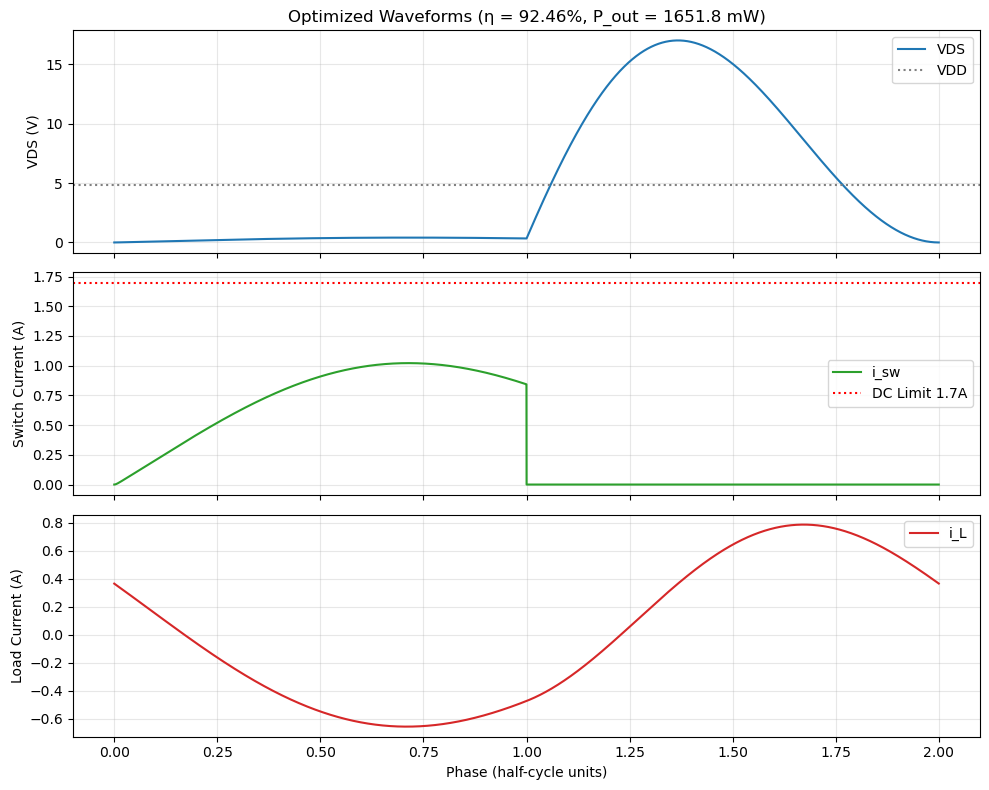

In [1]:
# =============================================================================
# CONSOLIDATED EPC2037 GaN CLASS-E AMPLIFIER NOTEBOOK
# Principled Optimization: Maximize Efficiency with 5 DOF and 3 Equalities
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq, minimize
from scipy.interpolate import PchipInterpolator
import pandas as pd
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# --- Specs ---
VDD, POUT_TARGET, F0 = 4.85, 1.65, 14.0e6
W0, T, TH = 2*np.pi*F0, 1/F0, 1/(2*F0)
VDS_MAX, ID_MAX = 100.0, 1.7
RON_25 = 0.400
QG, VG = 115e-12, 5.0
PGATE = QG*VG*F0
COSS_50, QOSS_50, COSS_TR = 6.5e-12, 600e-12, 12e-12

# Analytical starting point
a = 2/np.sqrt(np.pi**2 + 4)
Ropt_ana = 2*a**2*VDD**2/POUT_TARGET
phi = np.pi - np.arctan(2/np.pi)
IR_norm = np.sqrt(2/(2*a**2))
IDC_norm = a*IR_norm
C_norm = (2*a**2/np.pi)/(2*a**2)
th = np.linspace(0, 2*np.pi, 200001)
vd_norm = np.zeros_like(th)
off = th >= np.pi
vd_norm[off] = (IDC_norm*(th[off]-np.pi) + IR_norm*(np.cos(th[off]+phi)-np.cos(np.pi+phi)))/C_norm
V1 = np.trapezoid(vd_norm*np.exp(-1j*th), th)/np.pi
I1 = IR_norm*np.exp(1j*(phi-np.pi/2))
KL = (V1/I1).imag/(V1/I1).real
L1_ana = KL*Ropt_ana/W0
L2_ana = 3.0*Ropt_ana/W0
C2_ana = 1/(W0**2*L2_ana)
LT_ana = L1_ana+L2_ana

# =============================================================================
# Datasheet & Coss Models
# =============================================================================
DS_FIG5_VDS = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100.])
DS_FIG5_COSS = 1e-12*np.array([22.0, 15.5, 11.5, 9.8, 8.5, 7.5, 7.0, 6.7, 6.5, 5.8, 5.1, 4.5])
_coss_dig = PchipInterpolator(DS_FIG5_VDS, DS_FIG5_COSS, extrapolate=False)
V_GRID = np.linspace(0, 150, 150001)
C_GRID_RAW = _coss_dig(np.clip(V_GRID, 0, 100))
Q_GRID_RAW = cumulative_trapezoid(C_GRID_RAW, V_GRID, initial=0)
Q_RAW_50 = Q_GRID_RAW[np.argmin(np.abs(V_GRID-50))]
CAL_A = (QOSS_50-Q_RAW_50)/25.0
C_GRID = C_GRID_RAW.copy()
C_GRID[V_GRID <= 50] += CAL_A*(1-V_GRID[V_GRID <= 50]/50)
Q_GRID = cumulative_trapezoid(C_GRID, V_GRID, initial=0)
E_GRID = cumulative_trapezoid(V_GRID*C_GRID, V_GRID, initial=0)
_coss_tab, _qoss_tab, _eoss_tab = PchipInterpolator(V_GRID, C_GRID), PchipInterpolator(V_GRID, Q_GRID), PchipInterpolator(V_GRID, E_GRID)

def coss_tab(v): return _coss_tab(np.clip(np.abs(v), 0, 150))
def qoss_tab(v): return np.sign(v)*_qoss_tab(np.abs(v))
def eoss_tab(v): return _eoss_tab(np.abs(v))

# =============================================================================
# Simulation Engine
# =============================================================================
class DeviceModel:
    def __init__(self, coss_f, qoss_f, eoss_f, Cext, Ron):
        self.coss_f, self.qoss_f, self.eoss_f = coss_f, qoss_f, eoss_f
        self.Cext, self.Ron = float(Cext), float(Ron)
        self._vg = np.linspace(0, 150, 150001)
        self._qg = self.Cext*self._vg + np.asarray(self.qoss_f(self._vg), float)
    def v_from_q(self, q):
        q = float(q)
        if abs(q) < 1e-30: return 0.0
        return np.sign(q)*float(np.interp(abs(q), self._qg, self._vg))

def cycle_nonlin(IDC, dev, LT_val, C2_val, Ropt_val, warmup=100, samples=400):
    def f_on(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL-vD/dev.Ron, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    def f_off(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    y = np.zeros(3)
    for _ in range(warmup):
        s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12)
        s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12)
        y = s2.y[:, -1]
    s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    t1, t2 = np.linspace(0, TH, samples, endpoint=False), np.linspace(0, TH, samples, endpoint=False)
    y1, y2 = s1.sol(t1), s2.sol(t2)
    q = np.r_[y1[0], y2[0]]; iL = np.r_[y1[1], y2[1]]
    t = np.r_[t1, TH+t2]; vD = np.array([dev.v_from_q(z) for z in q]); iSW = np.r_[vD[:samples]/dev.Ron, np.zeros(samples)]
    return {"t": t, "v_D": vD, "i_L": iL, "i_sw": iSW, "v_avg": np.trapezoid(vD, t)/T,
            "v_turnon": float(dev.v_from_q(s2.y[0, -1])), "i_turnon": float(s2.y[1, -1])}

def solve_nonlin(dev, LT_val, C2_val, Ropt_val, warmup=50, samples=200):
    def resid(I): return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup, samples=samples)["v_avg"] - VDD
    I = brentq(resid, 0.05*POUT_TARGET/VDD, 3.0*POUT_TARGET/VDD, xtol=1e-8)
    return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup*2, samples=samples*2), I

# =============================================================================
# Principled Optimization Setup (5 DOF, 3 Equalities)
# =============================================================================
print("Running Principled Optimization (5 DOF, Maximize Efficiency)...")
print("This will find the network that hits exactly 1.65 W with ZVS/ZDS.")

# Variables to optimize (scaled units for numerical stability):
# [Cext (pF), L1 (nH), L2 (nH), C2 (pF), Ropt (Ohm)]
x0_scaled = [247.33, 107.73, 280.44, 460.83, Ropt_ana]
bounds_scaled = [(100, 400), (50, 200), (150, 400), (200, 800), (2.0, 20.0)]

cache = {}
def eval_design(x):
    key = tuple(np.round(x, 5))
    if key in cache: return cache[key]
    
    Cext, L1_val, L2_val, C2_val, Ropt_val = x[0]*1e-12, x[1]*1e-9, x[2]*1e-9, x[3]*1e-12, x[4]
    LT_val = L1_val + L2_val
    dev = DeviceModel(coss_tab, qoss_tab, eoss_tab, Cext, RON_25)
    
    try:
        h, I = solve_nonlin(dev, LT_val, C2_val, Ropt_val, warmup=20, samples=100)
        P_load = np.trapezoid(Ropt_val*h["i_L"]**2, h["t"])/T
        P_in = VDD * I
        eta = P_load / (P_in + PGATE)
        
        C_sh_tot = Cext + dev.coss_f(h["v_turnon"])
        dVdt = (I - h["i_turnon"]) / C_sh_tot
        
        # Return metrics for constraints and objective
        res = (h["v_turnon"], dVdt, P_load, eta, P_in, np.max(h["i_sw"]), np.max(h["v_D"]))
    except Exception:
        res = (10.0, 10.0, 0.0, 0.0, 10.0, 10.0, 10.0)
        
    cache[key] = res
    return res

def obj(x): return -eval_design(x)[3] # Maximize efficiency
def con_zvs(x): return eval_design(x)[0]
def con_zds(x): return eval_design(x)[1] * 1e-8 # Scale dV/dt
def con_power(x): return eval_design(x)[2] - POUT_TARGET # Enforce P_out = 1.65 W

cons = [
    {'type': 'eq', 'fun': con_zvs},
    {'type': 'eq', 'fun': con_zds},
    {'type': 'eq', 'fun': con_power}
]

res_opt = minimize(obj, x0_scaled, method='SLSQP', bounds=bounds_scaled, constraints=cons,
                   options={'maxiter': 300, 'eps': 1e-4})

# =============================================================================
# Post-Computation Diagnostics
# =============================================================================
Cext_t, L1_t, L2_t, C2_t, Ropt_t = res_opt.x[0]*1e-12, res_opt.x[1]*1e-9, res_opt.x[2]*1e-9, res_opt.x[3]*1e-12, res_opt.x[4]
LT_t = L1_t + L2_t

dev_tuned = DeviceModel(coss_tab, qoss_tab, eoss_tab, Cext_t, RON_25)
h_tuned, I_tuned = solve_nonlin(dev_tuned, LT_t, C2_t, Ropt_t, warmup=500, samples=1600)

P_load_final = np.trapezoid(Ropt_t*h_tuned["i_L"]**2, h_tuned["t"])/T
P_in_final = VDD * I_tuned
eta_final = P_load_final / (P_in_final + PGATE)

print("\n### OPTIMIZATION RESULTS & DIAGNOSTICS\n")
print(f"**Optimizer Exit Status:** {res_opt.message}")
print(f"**Objective (Efficiency):** {eta_final*100:.4f} %\n")

print("**1) Resulting Component Values:**")
print(f"- $C_{{ext}}$ = {Cext_t*1e12:.2f} pF")
print(f"- $L_1$     = {L1_t*1e9:.2f} nH")
print(f"- $L_2$     = {L2_t*1e9:.2f} nH")
print(f"- $C_2$     = {C2_t*1e12:.2f} pF")
print(f"- $R_{{opt}}$   = {Ropt_t:.3f} Ω")

print("\n**2) Fulfillment of Constraints (ZVS, ZDS, Power):**")
print(f"- $V_{{DS}}(t_{{on}})$ = {h_tuned['v_turnon']*1e3:.3f} mV")
print(f"- $dV_{{DS}}/dt(t_{{on}})$ = {(I_tuned - h_tuned['i_turnon'])/(Cext_t + dev_tuned.coss_f(h_tuned['v_turnon']))/1e9:.3f} kV/µs")
print(f"- $P_{{out}}$ = {P_load_final*1e3:.2f} mW (Target: {POUT_TARGET*1e3:.2f} mW)")

print("\n**3) Post-Computation Diagnostics:**")
print(f"- Peak Voltage:   {np.max(h_tuned['v_D']):.2f} V (SOA limit 100 V)")
print(f"- Peak Current:   {np.max(h_tuned['i_sw']):.2f} A (Pulsed SOA ~2.5 A)")
print(f"- Input Power:    {P_in_final*1e3:.2f} mW")
print(f"- Losses:         {(P_in_final + PGATE - P_load_final)*1e3:.2f} mW")

if abs(h_tuned['v_turnon']) < 0.01 and abs((I_tuned - h_tuned['i_turnon'])/(Cext_t + dev_tuned.coss_f(h_tuned['v_turnon']))) < 1e9 and abs(P_load_final - POUT_TARGET) < 0.05:
    print("\n**Overall Status:** PASS - True Class-E operating point found.")
else:
    print("\n**Overall Status:** FAIL - Constraints not perfectly satisfied.")

# =============================================================================
# Plotting
# =============================================================================
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ph = h_tuned["t"]/TH
ax[0].plot(ph, h_tuned["v_D"], "C0-", lw=1.5, label="VDS")
ax[0].axhline(VDD, color="gray", ls=":", label="VDD")
ax[0].set_ylabel("VDS (V)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[0].set_title(f"Optimized Waveforms (η = {eta_final*100:.2f}%, P_out = {P_load_final*1e3:.1f} mW)")

ax[1].plot(ph, h_tuned["i_sw"], "C2-", lw=1.5, label="i_sw")
ax[1].axhline(ID_MAX, color="red", ls=":", label="DC Limit 1.7A")
ax[1].set_ylabel("Switch Current (A)"); ax[1].legend(); ax[1].grid(alpha=0.3)

ax[2].plot(ph, h_tuned["i_L"], "C3-", lw=1.5, label="i_L")
ax[2].set_ylabel("Load Current (A)"); ax[2].set_xlabel("Phase (half-cycle units)"); ax[2].legend(); ax[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()